In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix


In [2]:
df_train=pd.read_csv('train.csv')
df_test= pd.read_csv('test.csv')

In [3]:
df_train

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
X = df_train.iloc[:,1:]
y = df_train.iloc[:,0]


In [5]:
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.1)

In [7]:
x_train = np.array(x_train).reshape(-1, 28, 28, 1)
x_val = np.array(x_val).reshape(-1, 28, 28, 1)

print(x_train.shape)
print(x_val.shape)

(37800, 28, 28, 1)
(4200, 28, 28, 1)


In [8]:
x_train = x_train.astype('float32')/255
x_val = x_val.astype('float32')/255

In [9]:
from keras.utils import to_categorical
y_train = to_categorical(y_train)
y_val = to_categorical(y_val)
#example:
print(y_train[0])

[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


In [ ]:
%pip install tensorflow



^C
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Using cached grpcio-1.84.0-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/384.1 MB 1.5 MB/s eta 0:04:17
   ---------------------------------------- 0.5/384.1 MB 1.5 MB/s eta 0:04:17
   ---------------------------------------- 0.8/384.1 MB 867.7 kB/s eta 0:07:22
   ---------------------------------------- 0.8/384.1 MB 867.7 kB/s eta 0:07:22
   ---------------------------------------- 1.0/384.1 MB 816.0 kB/s eta 0:07:50
   ---------------------------------------- 1.0/384.1 MB 816.0 kB/s eta 0:07:50
   ---------------------------------------- 1.0/384.1 MB 816.0 kB/s eta 0:07:50
   ---------------------------------------- 1.3/384.1 MB 653.6 kB/s eta 0:09:46
   ---------------------------------------- 1.3/384.1 MB 653.6 kB/s eta 0:09:46
   ---------------------------------------- 1.6/384.1 MB 605.5 kB/s e

In [10]:
from keras.models import Sequential #Sequential Model/API for our model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D, BatchNormalization

from keras.optimizers import Adam #for optimizationfrom keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator #random data from our train set
from keras.callbacks import LearningRateScheduler # adjust LR each epoch

In [11]:
model = Sequential()
input_shape = (28, 28, 1)

# Layer One
model.add(Conv2D(filters=16, kernel_size=(3, 3), activation='relu',input_shape=input_shape))
model.add(BatchNormalization())

#Layers
model.add(Conv2D(filters=16, kernel_size=(3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPool2D(strides=(2,2)))
model.add(Dropout(0.25))

# Layers
model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu'))
model.add(BatchNormalization())

# Layers
model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPool2D(strides=(2,2)))
model.add(Dropout(0.25))

# Utility Layer
model.add(Flatten())

# Dense Layer
model.add(Dense(512,activation='relu'))
model.add(Dropout(0.25))
model.add(Dense(1024,activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 10, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 814,970 (3.11 MB)

 Trainable params: 814,778 (3.11 MB)

 Non-trainable params: 192 (768.00 B)

In [13]:
datagen = ImageDataGenerator(zoom_range = 0.1,height_shift_range = 0.1,
                             width_shift_range = 0.1,rotation_range = 10)

In [14]:

model.compile(loss='categorical_crossentropy', optimizer = Adam(learning_rate=1e-4), metrics=["accuracy"])

In [15]:
annealer = LearningRateScheduler(lambda x: 1e-3 * 0.9 ** x)

In [16]:
history = model.fit(datagen.flow(x_train, y_train, batch_size=10), #data augmentation
                             steps_per_epoch=500, #training samples per epoch 500 * 15 = 7500 training samples
                             epochs=40, #No of iterations of training
                             verbose=2, #output of the training
                             validation_data=(x_val,y_val), #model evaluation at each epoch
                             callbacks=[annealer]) #learning rate adjuster

Epoch 1/40
500/500 - 27s - 53ms/step - accuracy: 0.7106 - loss: 0.9357 - val_accuracy: 0.9129 - val_loss: 0.2853 - learning_rate: 0.0010
Epoch 2/40
500/500 - 6s - 12ms/step - accuracy: 0.8714 - loss: 0.4310 - val_accuracy: 0.9560 - val_loss: 0.1526 - learning_rate: 9.0000e-04
Epoch 3/40
500/500 - 5s - 9ms/step - accuracy: 0.9060 - loss: 0.3040 - val_accuracy: 0.9676 - val_loss: 0.1088 - learning_rate: 8.1000e-04
Epoch 4/40
500/500 - 4s - 9ms/step - accuracy: 0.9242 - loss: 0.2504 - val_accuracy: 0.9764 - val_loss: 0.0767 - learning_rate: 7.2900e-04
Epoch 5/40
500/500 - 6s - 11ms/step - accuracy: 0.9392 - loss: 0.2224 - val_accuracy: 0.9800 - val_loss: 0.0751 - learning_rate: 6.5610e-04
Epoch 6/40
500/500 - 4s - 9ms/step - accuracy: 0.9380 - loss: 0.2203 - val_accuracy: 0.9840 - val_loss: 0.0534 - learning_rate: 5.9049e-04
Epoch 7/40
500/500 - 5s - 9ms/step - accuracy: 0.9450 - loss: 0.1866 - val_accuracy: 0.9795 - val_loss: 0.0636 - learning_rate: 5.3144e-04
Epoch 8/40


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


500/500 - 3s - 6ms/step - accuracy: 0.9461 - loss: 0.1669 - val_accuracy: 0.9848 - val_loss: 0.0538 - learning_rate: 4.7830e-04
Epoch 9/40
500/500 - 5s - 9ms/step - accuracy: 0.9462 - loss: 0.1721 - val_accuracy: 0.9840 - val_loss: 0.0583 - learning_rate: 4.3047e-04
Epoch 10/40
500/500 - 5s - 9ms/step - accuracy: 0.9574 - loss: 0.1563 - val_accuracy: 0.9843 - val_loss: 0.0486 - learning_rate: 3.8742e-04
Epoch 11/40
500/500 - 6s - 12ms/step - accuracy: 0.9604 - loss: 0.1291 - val_accuracy: 0.9843 - val_loss: 0.0518 - learning_rate: 3.4868e-04
Epoch 12/40
500/500 - 5s - 9ms/step - accuracy: 0.9614 - loss: 0.1354 - val_accuracy: 0.9838 - val_loss: 0.0518 - learning_rate: 3.1381e-04
Epoch 13/40
500/500 - 5s - 10ms/step - accuracy: 0.9658 - loss: 0.1119 - val_accuracy: 0.9869 - val_loss: 0.0453 - learning_rate: 2.8243e-04
Epoch 14/40
500/500 - 6s - 12ms/step - accuracy: 0.9668 - loss: 0.1181 - val_accuracy: 0.9862 - val_loss: 0.0406 - learning_rate: 2.5419e-04
Epoch 15/40
500/500 - 5s - 9ms

In [17]:
final_loss, final_acc = model.evaluate(x_val, y_val, verbose=0)
print("Model 1 - Final Loss: {}, and Final Accuracy: {}".format(final_loss, final_acc))

Model 1 - Final Loss: 0.02539239078760147, and Final Accuracy: 0.9909523725509644


In [20]:
import matplotlib.pyplot as plt #visualizations
%matplotlib inline
import seaborn as sns

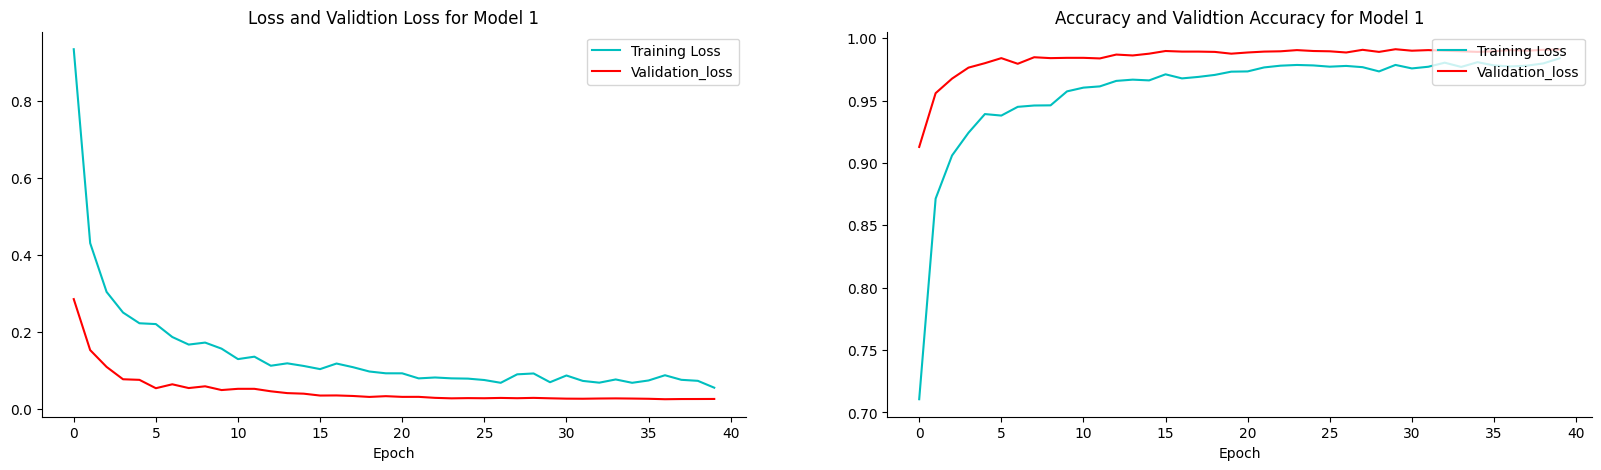

In [21]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], color='c',label='Training Loss')
plt.plot(history.history['val_loss'], color='r', label='Validation_loss')
plt.xlabel("Epoch")
plt.ylabel("")
plt.title("Loss and Validtion Loss for Model 1")
plt.legend(loc='upper right')
sns.despine()


plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], color='c',label='Training Loss')
plt.plot(history.history['val_accuracy'], color='r', label='Validation_loss')
plt.xlabel("Epoch")
plt.ylabel("")
plt.title("Accuracy and Validtion Accuracy for Model 1")
sns.despine()
plt.legend(loc='upper right')

plt.show()


132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


<Figure size 2000x1000 with 0 Axes>

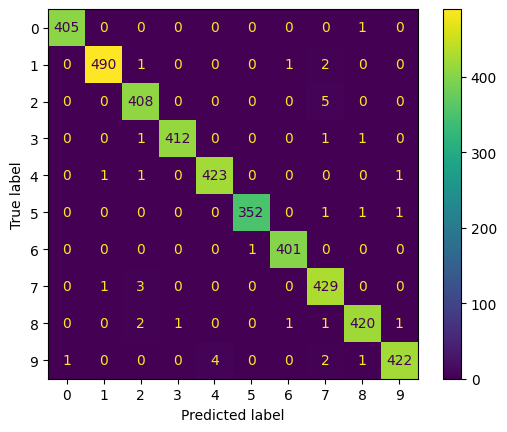

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
plt.figure(figsize=(20,10))
y_hat = model.predict(x_val)
y_pred = np.argmax(y_hat, axis=1)
y_true = np.argmax(y_val, axis=1)
cm = confusion_matrix(y_true, y_pred)
# mask=np.triu(np.ones(cm.shape),k=1)
# np.fill_diagonal(cm,0)
# sns.heatmap(data=cm, annot=True, cmap='viridis',mask=mask)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()